In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/faiss/D2/'

In [2]:
df_flat = pd.read_csv(main_dir + 'faiss_flat.csv')
df_flat['index'] = 'flat'
df_hnsw = pd.read_csv(main_dir + 'faiss_hnsw.csv')
df_hnsw['index'] = 'hnsw'
df_lsh = pd.read_csv(main_dir + 'faiss_lsh.csv')
df_lsh['index'] = 'lsh'

In [3]:
result = pd.DataFrame()
dfs = [df_flat, df_hnsw, df_lsh]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,1064,1,72.18,72.18,72.18,768,296,780,296,flat,[name],1024,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,2128,2,39.71,79.42,52.94,845,1283,857,219,flat,[name],1024,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,3192,3,27.91,83.74,41.87,891,2301,903,173,flat,[name],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,4256,4,21.92,87.69,35.08,933,3323,945,131,flat,[name],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,5320,5,17.86,89.29,29.76,950,4370,962,114,flat,[name],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,FAISS LSH Blocking,6384,6,14.68,88.06,25.16,937,5447,949,127,lsh,[name],1024,0,32,salted_qgrams,,4
956,FAISS LSH Blocking,7448,7,12.67,88.72,22.18,944,6504,956,120,lsh,[name],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,8512,8,11.10,88.82,19.74,945,7567,957,119,lsh,[name],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,9576,9,9.94,89.47,17.89,952,8624,964,112,lsh,[name],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[name]    960
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    960
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    960
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    960
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    960
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     30
2     30
3     30
4     30
5     30
6     30
7     30
8     30
9     30
10    30
11    30
12    30
13    30
14    30
15    30
16    30
17    30
18    30
19    30
20    30
21    30
22    30
23    30
24    30
25    30
26    30
27    30
28    30
29    30
30    30
31    30
32    30
Name: count, dtype: int64

In [10]:
valid_rows = result[result['Recall %']>=80]
valid_rows

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
2,FAISS FLAT Blocking,3192,3,27.91,83.74,41.87,891,2301,903,173,flat,[name],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,4256,4,21.92,87.69,35.08,933,3323,945,131,flat,[name],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,5320,5,17.86,89.29,29.76,950,4370,962,114,flat,[name],1024,0,1,salted_qgrams,,4
5,FAISS FLAT Blocking,6384,6,14.96,89.76,25.64,955,5429,967,109,flat,[name],1024,0,1,salted_qgrams,,4
6,FAISS FLAT Blocking,7448,7,12.92,90.41,22.60,962,6486,974,102,flat,[name],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,FAISS LSH Blocking,6384,6,14.68,88.06,25.16,937,5447,949,127,lsh,[name],1024,0,32,salted_qgrams,,4
956,FAISS LSH Blocking,7448,7,12.67,88.72,22.18,944,6504,956,120,lsh,[name],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,8512,8,11.10,88.82,19.74,945,7567,957,119,lsh,[name],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,9576,9,9.94,89.47,17.89,952,8624,964,112,lsh,[name],1024,0,32,salted_qgrams,,4


In [11]:
max_f1 = valid_rows.loc[valid_rows.groupby(['num_hashes','index'])['F1 %'].idxmax()]
max_f1

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
2,FAISS FLAT Blocking,3192,3,27.91,83.74,41.87,891,2301,903,173,flat,[name],1024,0,1,salted_qgrams,,4
322,FAISS HNSW Blocking,3192,3,27.47,82.42,41.21,877,2315,889,187,hnsw,[name],1024,0,1,salted_qgrams,,4
642,FAISS LSH Blocking,3192,3,27.91,83.74,41.87,891,2301,903,173,lsh,[name],1024,0,1,salted_qgrams,,4
11,FAISS FLAT Blocking,2128,2,40.08,80.17,53.45,853,1275,865,211,flat,[name],1024,0,2,salted_qgrams,,4
332,FAISS HNSW Blocking,3192,3,27.82,83.46,41.73,888,2304,900,176,hnsw,[name],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
623,FAISS HNSW Blocking,4256,4,20.28,81.11,32.44,863,3393,875,201,hnsw,[name],1024,0,31,salted_qgrams,,4
942,FAISS LSH Blocking,3192,3,27.57,82.71,41.35,880,2312,892,184,lsh,[name],1024,0,31,salted_qgrams,,4
312,FAISS FLAT Blocking,3192,3,27.51,82.52,41.26,878,2314,890,186,flat,[name],1024,0,32,salted_qgrams,,4
633,FAISS HNSW Blocking,4256,4,20.07,80.26,32.11,854,3402,866,210,hnsw,[name],1024,0,32,salted_qgrams,,4


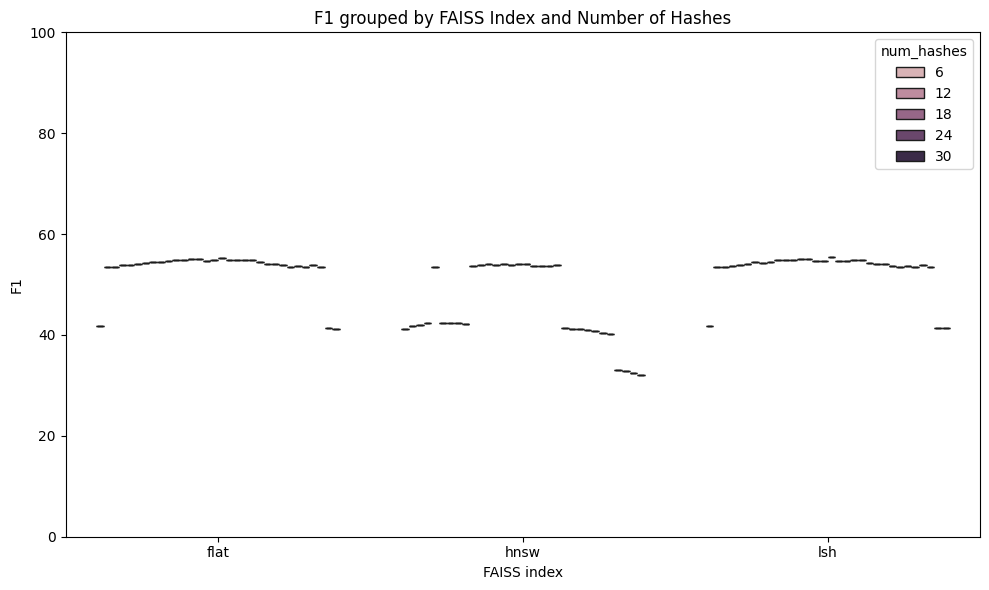

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="index",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by FAISS Index and Number of Hashes")
plt.xlabel("FAISS index")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [13]:
metrics_df = max_f1.melt(
    id_vars=["index", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,index,num_hashes,Metric,Score
0,flat,1,Precision %,27.91
1,hnsw,1,Precision %,27.47
2,lsh,1,Precision %,27.91
3,flat,2,Precision %,40.08
4,hnsw,2,Precision %,27.82
...,...,...,...,...
283,hnsw,31,F1 %,32.44
284,lsh,31,F1 %,41.35
285,flat,32,F1 %,41.26
286,hnsw,32,F1 %,32.11


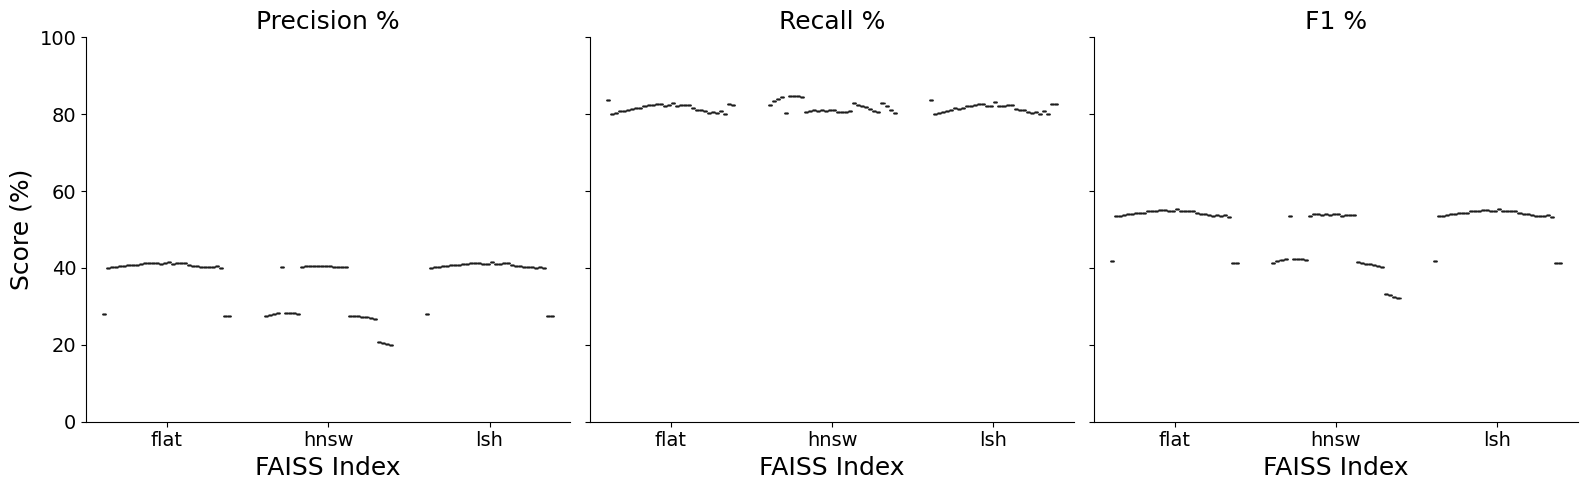

In [14]:
g = sns.catplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("FAISS Index", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

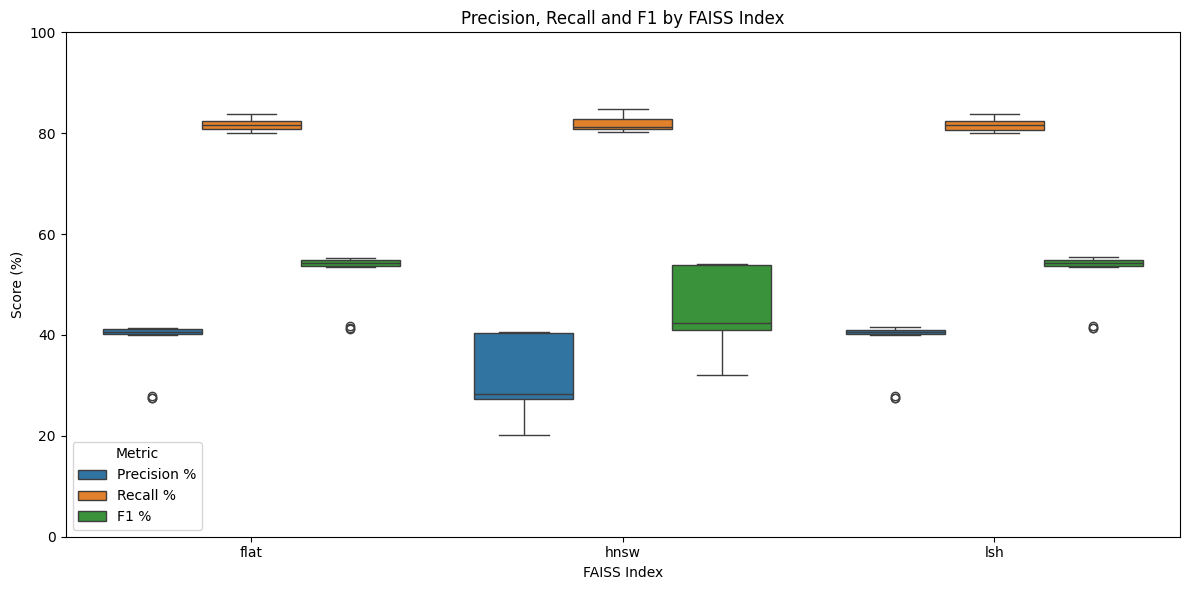

In [15]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by FAISS Index")
plt.xlabel("FAISS Index")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()